# Stage 1: Exploratory Data Analysis & Pandas/Regex Cleaning

Inspect all cleaned CarDekho CSV files in `data/`, verify Regex specification parsing via `src/pipeline.py`, and examine price distributions and top brands.

In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.pipeline import list_data_files, clean_specifications

files = list_data_files()
print('Discovered datasets:', [f.name for f in files])

Discovered datasets: ['Car details v3.csv', 'car details v4.csv', 'CAR DETAILS FROM CAR DEKHO.csv', 'car data.csv']


In [2]:
summary_rows = []
for path in files:
    clean_df, audit_df, _ = clean_specifications(path)
    summary_rows.append({
        'Dataset': path.name,
        'Rows': len(clean_df),
        'Columns': clean_df.shape[1],
        'Brands': clean_df['brand'].nunique(),
        'Year Range': f"{clean_df['year'].min()}-{clean_df['year'].max()}",
        'Median Price (L)': round(clean_df['price_lakh'].median(), 2),
    })
print(pd.DataFrame(summary_rows).to_string(index=False))

                       Dataset  Rows  Columns  Brands Year Range  Median Price (L)
            Car details v3.csv  6908       13      32  1983-2020              4.00
            car details v4.csv  2054       12      33  1988-2022              8.25
CAR DETAILS FROM CAR DEKHO.csv  3577        8      29  1992-2020              3.50
                  car data.csv   299        8      44  2003-2018              3.51


In [3]:
v3_df, v3_audit, v3_sample = clean_specifications(ROOT / 'data' / 'Car details v3.csv')
print('=== Regex Audit: Car details v3.csv ===')
print(v3_audit.to_string(index=False))
print('\n=== Raw vs Cleaned Sample (First 6 Rows) ===')
print(v3_sample.head(6).to_string(index=False))

=== Regex Audit: Car details v3.csv ===
       Field    Source                     Regex  Parsed  Raw Non-Null
mileage_kmpl   mileage           (\d+(?:\.\d+)?)    6908          6908
   engine_cc    engine           (\d+(?:\.\d+)?)    6908          6908
   power_bhp max_power           (\d+(?:\.\d+)?)    6908          6908
   torque_nm    torque (\d+(?:\.\d+)?) + kgm->Nm    6702          6908

=== Raw vs Cleaned Sample (First 6 Rows) ===
                     Raw Name   Brand  Raw mileage  Mileage (kmpl)  Raw engine  Engine (cc)  Raw max_power  Power (bhp)               Raw torque  Torque (Nm)
       Maruti Swift Dzire VDI  Maruti        23.40            23.4        1248         1248          74.00         74.0           190Nm@ 2000rpm        190.0
 Skoda Rapid 1.5 TDI Ambition   Skoda        21.14            21.1        1498         1498         103.52        103.5      250Nm@ 1500-2500rpm        250.0
     Honda City 2017-2020 EXi   Honda        17.70            17.7        1497       

In [4]:
v4_df, v4_audit, _ = clean_specifications(ROOT / 'data' / 'car details v4.csv')
print('=== Numeric Summary: Car details v3.csv ===')
print(v3_df[['price_lakh', 'year', 'km_driven', 'mileage_kmpl', 'engine_cc', 'power_bhp', 'torque_nm']].describe().round(2).to_string())
print('\n=== Cleaned Column Check: car details v4.csv ===')
print(v4_audit.to_string(index=False))

=== Numeric Summary: Car details v3.csv ===
       price_lakh     year   km_driven  mileage_kmpl  engine_cc  power_bhp  torque_nm
count     6908.00  6908.00     6908.00       6908.00    6908.00    6908.00    6702.00
mean         5.17  2013.42    74026.85         19.51    1425.19      87.59     174.32
std          5.19     4.08    58403.65          3.89     486.66      31.24     107.13
min          0.30  1983.00        1.00          9.00     624.00      32.80       4.80
25%          2.50  2011.00    40000.00         16.96    1197.00      68.00     110.00
50%          4.00  2014.00    70000.00         19.44    1248.00      81.83     160.00
75%          6.32  2017.00   100000.00         22.32    1498.00      99.00     200.06
max        100.00  2020.00  2360457.00         42.00    3604.00     400.00    1863.26

=== Cleaned Column Check: car details v4.csv ===
    Field        Source                     Regex  Parsed  Raw Non-Null
engine_cc     engine_cc           (\d+(?:\.\d+)?)    2059   

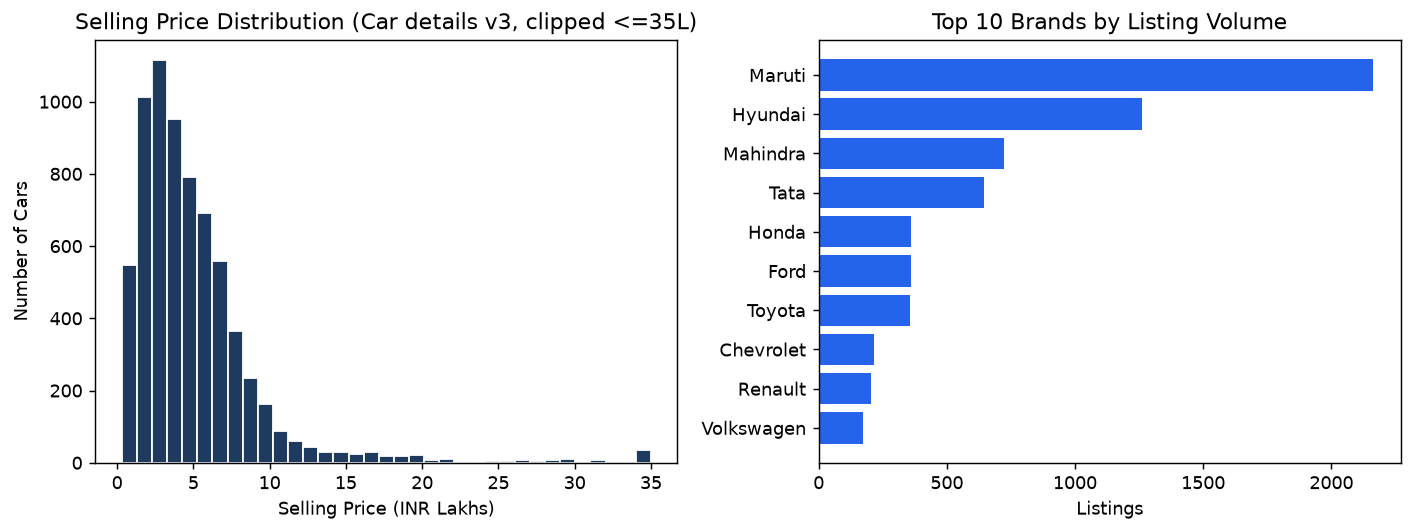

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

axes[0].hist(v3_df['price_lakh'].clip(upper=35), bins=35, color='#1E3A5F', edgecolor='white')
axes[0].set_title('Selling Price Distribution (Car details v3, clipped <=35L)')
axes[0].set_xlabel('Selling Price (INR Lakhs)')
axes[0].set_ylabel('Number of Cars')

top_brands = v3_df['brand'].value_counts().head(10).sort_values()
axes[1].barh(top_brands.index, top_brands.values, color='#2563EB')
axes[1].set_title('Top 10 Brands by Listing Volume')
axes[1].set_xlabel('Listings')

plt.tight_layout()
plt.show()